In [1]:
import json
import shap
import joblib
import numpy as np
import pandas as pd
import shap
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit
import warnings
from lightgbm.basic import LGBMDeprecationWarning

warnings.filterwarnings(
    "ignore",
    category=LGBMDeprecationWarning
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, fbeta_score, average_precision_score
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
from catboost import CatBoostClassifier

MODEL_DIR = Path("D:\\2026\\MedCare\\ML\\models")
MODEL_DIR.mkdir(exist_ok=True)

d:\2026\MedCare\ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd

TRAIN_DIR = r"D:\2026\MedCare\ML\Dataset\Clean\Train"
TEST_DIR = r"D:\2026\MedCare\ML\Dataset\Clean\Test"

t2d_train = pd.read_csv(fr"{TRAIN_DIR}\t2d_train_ft_engineered.csv")
t2d_test = pd.read_csv(fr"{TEST_DIR}\t2d_test_ft_engineered.csv")

cvd_train = pd.read_csv(fr"{TRAIN_DIR}\cvd_train_ft_engineered.csv")
cvd_test = pd.read_csv(fr"{TEST_DIR}\cvd_test_ft_engineered.csv")

print("T2D:", t2d_train.shape, t2d_test.shape)
print("CVD:", cvd_train.shape, cvd_test.shape)

T2D: (8926, 117) (2232, 117)
CVD: (8926, 141) (2232, 141)


In [3]:
for name, train, test, target in [
    ("T2D", t2d_train, t2d_test, "R16T2D"),
    ("CVD", cvd_train, cvd_test, "R16CVD")
]:
    print(f"\n{name}")
    print("Train:", train[target].value_counts(normalize=True))
    print("Test :", test[target].value_counts(normalize=True))


T2D
Train: R16T2D
0.0    0.670625
1.0    0.329375
Name: proportion, dtype: float64
Test : R16T2D
0.0    0.662186
1.0    0.337814
Name: proportion, dtype: float64

CVD
Train: R16CVD
0.0    0.67365
1.0    0.32635
Name: proportion, dtype: float64
Test : R16CVD
0.0    0.68414
1.0    0.31586
Name: proportion, dtype: float64


In [4]:
def split_train_val(df, test_size=0.2):
    split = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=42)
    tr, val = next(split.split(df, groups=df["HHIDPN"]))
    return df.iloc[tr].copy(), df.iloc[val].copy()

t2d_train, t2d_val = split_train_val(t2d_train)
cvd_train, cvd_val = split_train_val(cvd_train)

print("T2D:", t2d_train.shape, t2d_val.shape, t2d_test.shape)
print("CVD:", cvd_train.shape, cvd_val.shape, cvd_test.shape)

T2D: (7140, 117) (1786, 117) (2232, 117)
CVD: (7140, 141) (1786, 141) (2232, 141)


In [5]:
def get_xy(train, val, test, target, disease):
    past_targets = [f"R{w}{disease}" for w in [13, 14, 15]]
    drop = [target, "HHIDPN"] + past_targets

    return (
        train.drop(columns=drop),train[target],
        val.drop(columns=drop),val[target],
        test.drop(columns=drop),test[target]
    )

X_t2d_train, y_t2d_train, X_t2d_val, y_t2d_val, X_t2d_test, y_t2d_test = \
    get_xy(t2d_train, t2d_val, t2d_test, "R16T2D", "T2D")

X_cvd_train, y_cvd_train, X_cvd_val, y_cvd_val, X_cvd_test, y_cvd_test = \
    get_xy(cvd_train, cvd_val, cvd_test, "R16CVD", "CVD")

In [6]:
# def get_models(y_train):
#     class_counts = y_train.value_counts()
#     scale_pos_weight = np.sqrt(class_counts[0] / class_counts[1])
#     # scale_pos_weight=1

#     return {
#         "XGBoost": XGBClassifier(
#             n_estimators=1000,
#             max_depth=6,
#             learning_rate=0.05,
#             subsample=0.8,
#             colsample_bytree=0.8,
#             reg_lambda=15, 
#             reg_alpha=1,
#             random_state=42,
#             eval_metric=["logloss", "auc"],
#             early_stopping_rounds=30,
#             scale_pos_weight=scale_pos_weight
#         ),

#         "LightGBM": LGBMClassifier(
#             n_estimators=1000,
#             max_depth=6,
#             learning_rate=0.05,
#             bagging_fraction=0.8,
#             feature_fraction=0.8,
#             bagging_freq=1, 
#             lambda_l2=15,
#             random_state=42,
#             verbosity=-1,
#             scale_pos_weight=scale_pos_weight
#         ),

#         "CatBoost": CatBoostClassifier(
#             iterations=1000,
#             depth=3,
#             learning_rate=0.05,
#             subsample=0.8, 
#             l2_leaf_reg=15, 
#             random_seed=42,
#             verbose=False,
#             eval_metric="AUC",
#             auto_class_weights="Balanced",
#             od_type="Iter",
#             od_wait=30
#         )
#     }

In [7]:
def get_models(y_train, overrides=None):        
    overrides = overrides or {}
    class_counts = y_train.value_counts()
    scale_pos_weight = np.sqrt(class_counts[0] / class_counts[1])

    return {
        "XGBoost": XGBClassifier(**{
            "n_estimators": 1000, "max_depth": 3, "learning_rate": 0.05,
            "subsample": 0.8, "colsample_bytree": 0.8,
            "reg_lambda": 15, "reg_alpha": 1, "random_state": 42,
            "eval_metric": ["logloss", "auc"], "early_stopping_rounds": 30,
            "scale_pos_weight": scale_pos_weight,
            **overrides.get("XGBoost", {})    
        }),

        "LightGBM": LGBMClassifier(**{
            "n_estimators": 1000, "max_depth": 3, "learning_rate": 0.05,
            "bagging_fraction": 0.8, "feature_fraction": 0.8, "bagging_freq": 1,
            "lambda_l2": 15, "random_state": 42, "verbosity": -1,
            "scale_pos_weight": scale_pos_weight,
            **overrides.get("LightGBM", {})
        }),

        "CatBoost": CatBoostClassifier(**{
            "iterations": 1000, "depth": 8, "learning_rate": 0.05,
            "subsample": 0.8, "l2_leaf_reg": 15, "random_seed": 42,
            "verbose": False, "eval_metric": "AUC",
            "auto_class_weights": "Balanced", "od_type": "Iter", "od_wait": 30,
            **overrides.get("CatBoost", {})
        }),
    }


In [8]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def fit_one(name, model, X_tr, y_tr, X_vl, y_vl):
    if name == "LightGBM":
        model.fit(X_tr, y_tr, eval_set=[(X_vl, y_vl)], eval_names=["val"],
                  callbacks=[early_stopping(30, verbose=False)])
    else:
        model.fit(X_tr, y_tr, eval_set=[(X_vl, y_vl)], verbose=False)
    return model


SEARCH_SPACE = {
    "XGBoost":  {"max_depth": ("int", 2, 6),
                 "learning_rate": ("float", 0.01, 0.1),
                 "subsample": ("float", 0.6, 1.0),
                 "colsample_bytree": ("float", 0.6, 1.0),
                 "reg_lambda": ("float", 1, 20),
                 "reg_alpha": ("float", 0, 5)},
    "LightGBM": {"max_depth": ("int", 2, 6),
                 "learning_rate": ("float", 0.01, 0.1),
                 "bagging_fraction": ("float", 0.6, 1.0),
                 "feature_fraction": ("float", 0.6, 1.0),
                 "lambda_l2": ("float", 1, 20)},
    "CatBoost": {"depth": ("int", 4, 10),
                 "learning_rate": ("float", 0.01, 0.1),
                 "l2_leaf_reg": ("float", 1, 20),
                 "subsample": ("float", 0.6, 1.0)},
}

N_TRIALS = 50
best_params = {}

for disease, X_tr, y_tr, X_vl, y_vl in [
    ("T2D", X_t2d_train, y_t2d_train, X_t2d_val, y_t2d_val),
    ("CVD", X_cvd_train, y_cvd_train, X_cvd_val, y_cvd_val),
]:
    best_params[disease] = {}
    print(f"\n{'='*50}\n{disease}\n{'='*50}")

    for model_name, space in SEARCH_SPACE.items():

        def objective(trial, name=model_name, space=space):
            params = {
                k: trial.suggest_int(k, *v[1:]) if v[0] == "int"
                   else trial.suggest_float(k, *v[1:], log=(k == "learning_rate"))
                for k, v in space.items()
            }
            model = get_models(y_tr, {name: params})[name]   # ← tái dùng get_models
            fit_one(name, model, X_tr, y_tr, X_vl, y_vl)    # ← tái dùng fit_one
            return average_precision_score(y_vl, model.predict_proba(X_vl)[:, 1])

        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

        best_params[disease][model_name] = study.best_params
        print(f"{model_name:10s}  PR-AUC={study.best_value:.4f}  {study.best_params}")

with open(MODEL_DIR / "optuna_best_params_ft.json", "w") as f:
    json.dump(best_params, f, indent=2)
print("\nSaved: optuna_best_params.json")



T2D


Best trial: 10. Best value: 0.59741: 100%|██████████| 50/50 [00:37<00:00,  1.33it/s]


XGBoost     PR-AUC=0.5974  {'max_depth': 6, 'learning_rate': 0.0878354764896962, 'subsample': 0.9928820468877112, 'colsample_bytree': 0.9815747124211638, 'reg_lambda': 19.408273588027555, 'reg_alpha': 0.11719036402917427}


Best trial: 18. Best value: 0.598056: 100%|██████████| 50/50 [00:22<00:00,  2.18it/s]


LightGBM    PR-AUC=0.5981  {'max_depth': 3, 'learning_rate': 0.03987922105567145, 'bagging_fraction': 0.6734332640545962, 'feature_fraction': 0.7644614000425104, 'lambda_l2': 16.70025539207281}


Best trial: 46. Best value: 0.589922: 100%|██████████| 50/50 [00:50<00:00,  1.01s/it]


... (3 outputs left out)

Best trial: 27. Best value: 0.622993: 100%|██████████| 50/50 [00:17<00:00,  2.88it/s]


LightGBM    PR-AUC=0.6230  {'max_depth': 3, 'learning_rate': 0.0789844794638333, 'bagging_fraction': 0.9932177772538102, 'feature_fraction': 0.813542553847167, 'lambda_l2': 13.499798428666683}


Best trial: 24. Best value: 0.613621: 100%|██████████| 50/50 [01:04<00:00,  1.29s/it]

CatBoost    PR-AUC=0.6136  {'depth': 4, 'learning_rate': 0.034546661608730836, 'l2_leaf_reg': 2.4308166789865933, 'subsample': 0.6836792174121868}

Saved: optuna_best_params.json


In [9]:
def train_models(X_train, y_train, X_val, y_val, disease, overrides=None):
    models = get_models(y_train, overrides)
    histories = {}

    for name, model in models.items():

        if name == "XGBoost":
            model.fit(
                X_train, y_train,
                eval_set=[(X_train, y_train), (X_val, y_val)],
                verbose=False
            )
            histories[name] = model.evals_result()

        elif name == "LightGBM":
            model.fit(
                X_train, y_train,
                eval_set=[(X_train, y_train), (X_val, y_val)],
                eval_names=["train", "val"],
                callbacks=[early_stopping(30, verbose=False)]
            )
            histories[name] = model.evals_result_

        else:
            model.fit(
                X_train, y_train,
                eval_set=[(X_train, y_train), (X_val, y_val)],
                verbose=False
            )
            histories[name] = model.get_evals_result()

        best_iteration = getattr(model, "best_iteration_", None)
        if best_iteration is None:
            best_iteration = getattr(model, "best_iteration", None)

        print(f"{disease} - {name}: best iteration = {best_iteration}")

        joblib.dump(
            model,
            MODEL_DIR / f"{disease}_{name.lower()}.pkl"
        )

    with open(MODEL_DIR / f"{disease}_history.json", "w") as f:
        json.dump(histories, f, indent=2)

    return models, histories

In [10]:
with open(MODEL_DIR / "optuna_best_params_ft.json") as f:
    best_params = json.load(f)

t2d_ft_models, t2d_ft_history = train_models(
    X_t2d_train,
    y_t2d_train,
    X_t2d_val,
    y_t2d_val,
    "t2d",
    overrides=best_params["T2D"],
)

t2d - XGBoost: best iteration = 55
t2d - LightGBM: best iteration = 238
t2d - CatBoost: best iteration = 211


In [11]:
cvd_ft_models, cvd_ft_history = train_models(
    X_cvd_train,
    y_cvd_train,
    X_cvd_val,
    y_cvd_val,
    "cvd",
    overrides=best_params["CVD"]
)

cvd - XGBoost: best iteration = 318
cvd - LightGBM: best iteration = 123
cvd - CatBoost: best iteration = 356


In [12]:
def plot_loss(histories, disease):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (name, h) in zip(axes, histories.items()):

        if name == "XGBoost":
            train = h["validation_0"]["logloss"]
            val = h["validation_1"]["logloss"]

        elif name == "LightGBM":
            train = h["train"]["binary_logloss"]
            val = h["val"]["binary_logloss"]

        else:  # CatBoost
            train = h["learn"]["Logloss"]
            val_key = [k for k in h if k != "learn"][0]
            val = h[val_key]["Logloss"]

        ax.plot(train, label="Train Loss")
        ax.plot(val, label="Validation Loss")

        ax.set_title(name)
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Log Loss")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(f"{disease} - Loss Curve", fontsize=14)
    plt.tight_layout()
    plt.show()

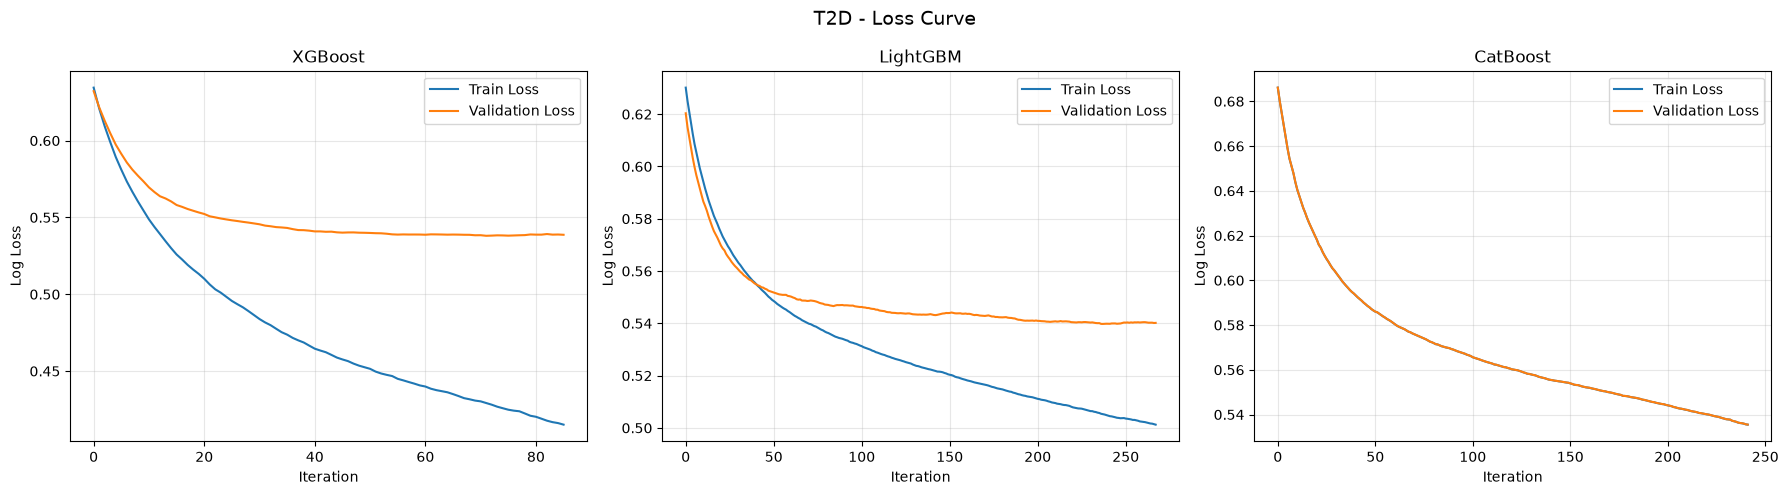

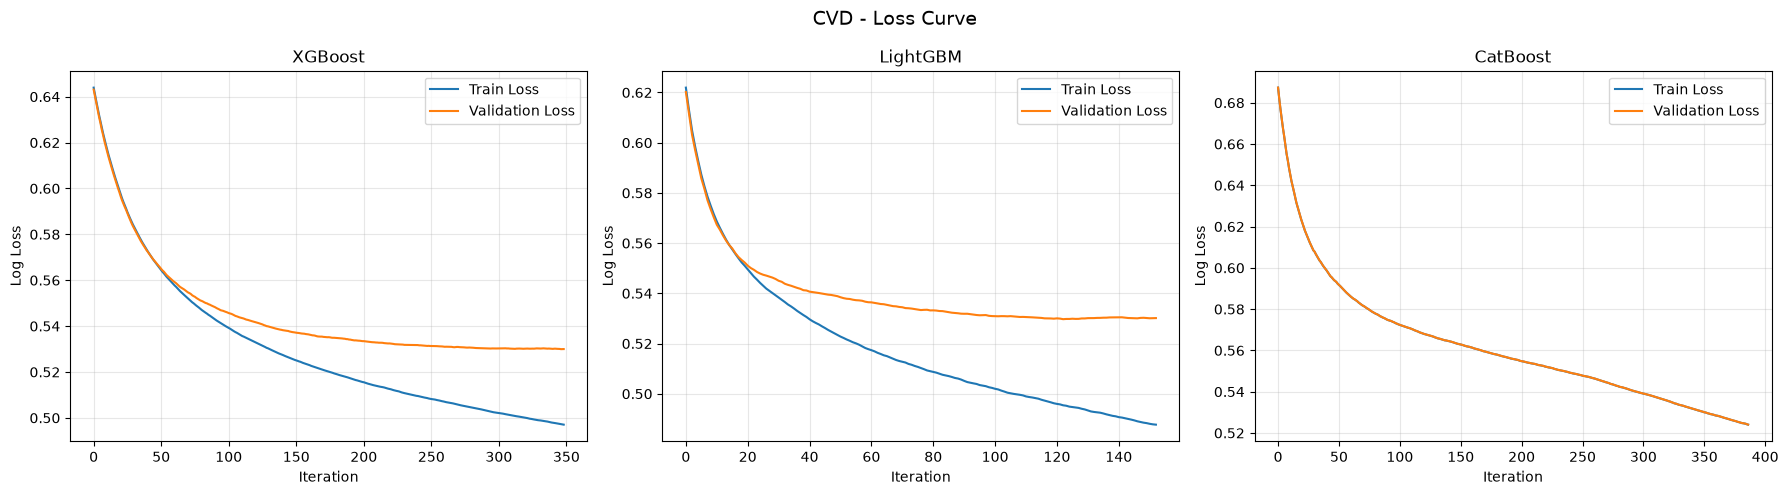

In [13]:
plot_loss(t2d_ft_history, "T2D")
plot_loss(cvd_ft_history, "CVD")

In [14]:
h = t2d_ft_history["CatBoost"]

val_key = [k for k in h if k != "learn"][0]

print("Train:", h["learn"]["Logloss"][:])
print("Val:  ", h[val_key]["Logloss"][:])

Train: [0.6861102761999807, 0.6800382392142426, 0.6746928394664738, 0.6693143618767118, 0.6638572348050583, 0.6588976578737297, 0.6543215483707114, 0.6511041393898214, 0.6479044982280825, 0.6438360260710744, 0.6404405804700433, 0.6377754075973556, 0.6351366048309011, 0.6324241705833529, 0.6302683759957275, 0.6278486243253221, 0.6257266756410368, 0.6238039620700585, 0.6219304044252623, 0.620013988957326, 0.6181735091545232, 0.6159214508781246, 0.6145846657064193, 0.6126283622525498, 0.6110181984455463, 0.6095368129243219, 0.6082267562874782, 0.6067348739278504, 0.6053883087749985, 0.6043832749009329, 0.6031725541982489, 0.6020057666045903, 0.600860535932726, 0.5995782831166291, 0.5985843605300443, 0.5975152703396726, 0.596646951385301, 0.595615393792733, 0.594773598556864, 0.5940680574038809, 0.5932090575938481, 0.5923660846639143, 0.5916521972442983, 0.5908899731639365, 0.5900145880451764, 0.5893130408111956, 0.5885382717288395, 0.5879301207546049, 0.587138147098085, 0.5865228787553719

In [15]:
def evaluate_models(models, X, y, dataset, threshold=0.5):
    results = []

    for name, model in models.items():
        prob = model.predict_proba(X)[:, 1]
        pred = (prob >= threshold).astype(int)

        results.append({
            "Model": name,
            "Dataset": dataset,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "F2": fbeta_score(y, pred, beta=2, zero_division=0),
            "ROC_AUC": roc_auc_score(y, prob),
            "PR_AUC": average_precision_score(y, prob)
        })

    return results

In [16]:
t2d_results = (
    evaluate_models(t2d_ft_models, X_t2d_val, y_t2d_val, "Validation")
    + evaluate_models(t2d_ft_models, X_t2d_test, y_t2d_test, "Test")
)

print(pd.DataFrame(t2d_results))

      Model     Dataset  Threshold  Accuracy  Precision    Recall        F1  \
0   XGBoost  Validation        0.5  0.717245   0.548239  0.630282  0.586405   
1  LightGBM  Validation        0.5  0.717245   0.548686  0.625000  0.584362   
2  CatBoost  Validation        0.5  0.678052   0.495897  0.744718  0.595355   
3   XGBoost        Test        0.5  0.716398   0.580774  0.576923  0.578842   
4  LightGBM        Test        0.5  0.731183   0.602941  0.598143  0.600533   
5  CatBoost        Test        0.5  0.688172   0.528713  0.708223  0.605442   

         F2   ROC_AUC    PR_AUC  
0  0.611966  0.767656  0.597410  
1  0.608085  0.768547  0.598056  
2  0.676800  0.764887  0.589922  
3  0.577689  0.769930  0.613667  
4  0.599097  0.773035  0.624058  
5  0.663189  0.769001  0.619510  


In [17]:
cvd_results = (
    evaluate_models(cvd_ft_models, X_cvd_val, y_cvd_val, "Validation")
    + evaluate_models(cvd_ft_models, X_cvd_test, y_cvd_test, "Test")
)

print(pd.DataFrame(cvd_results))

      Model     Dataset  Threshold  Accuracy  Precision    Recall        F1  \
0   XGBoost  Validation        0.5  0.724524   0.576389  0.572414  0.574394   
1  LightGBM  Validation        0.5  0.731243   0.588968  0.570690  0.579685   
2  CatBoost  Validation        0.5  0.700448   0.528662  0.715517  0.608059   
3   XGBoost        Test        0.5  0.721774   0.561047  0.547518  0.554200   
4  LightGBM        Test        0.5  0.718638   0.555396  0.547518  0.551429   
5  CatBoost        Test        0.5  0.678315   0.493306  0.679433  0.571599   

         F2   ROC_AUC    PR_AUC  
0  0.573204  0.777240  0.623194  
1  0.574254  0.776896  0.622993  
2  0.668277  0.776615  0.613621  
3  0.550171  0.752880  0.581948  
4  0.549075  0.752048  0.583681  
5  0.631759  0.752146  0.581506  


In [18]:
results = pd.DataFrame(t2d_results + cvd_results)

results.to_csv(
    MODEL_DIR / "model_metrics.csv",
    index=False
)

print("Đã lưu:", MODEL_DIR / "model_metrics.csv")

Đã lưu: D:\2026\MedCare\ML\models\model_metrics.csv


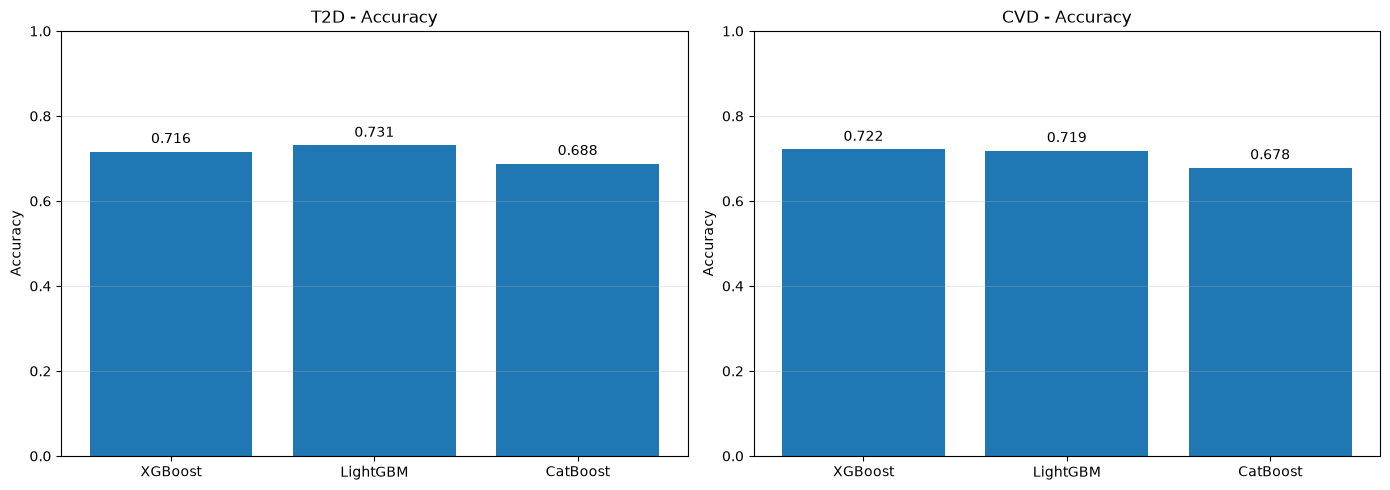

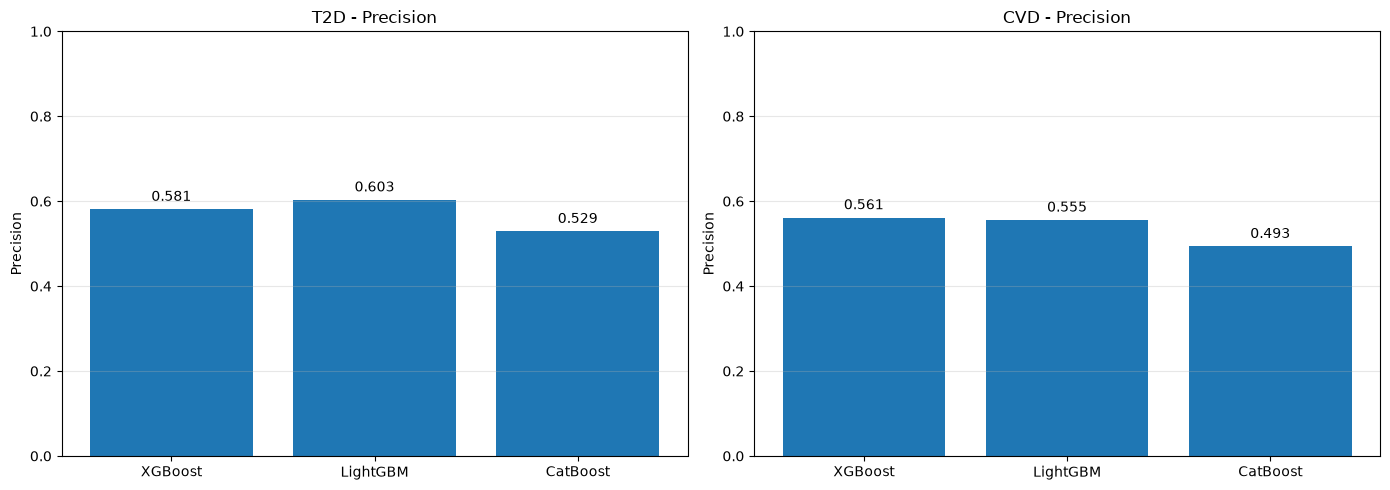

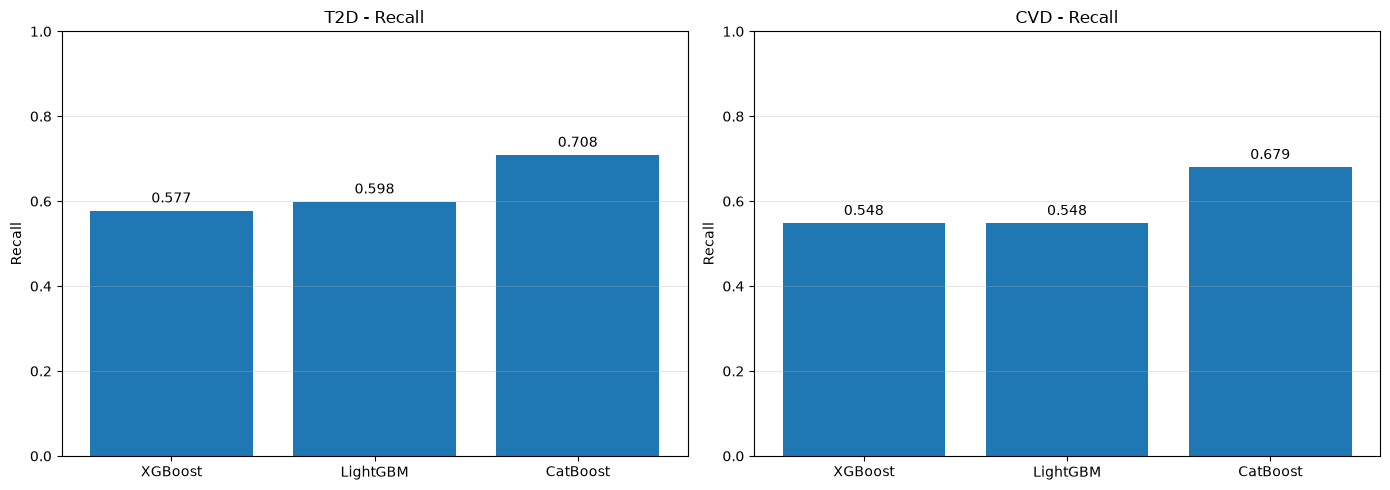

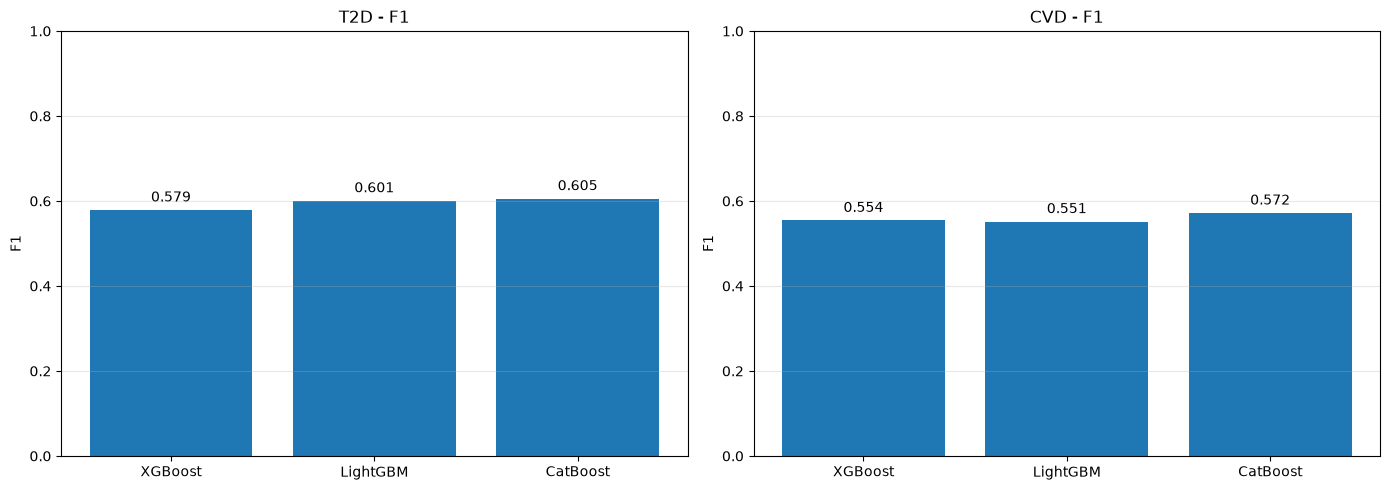

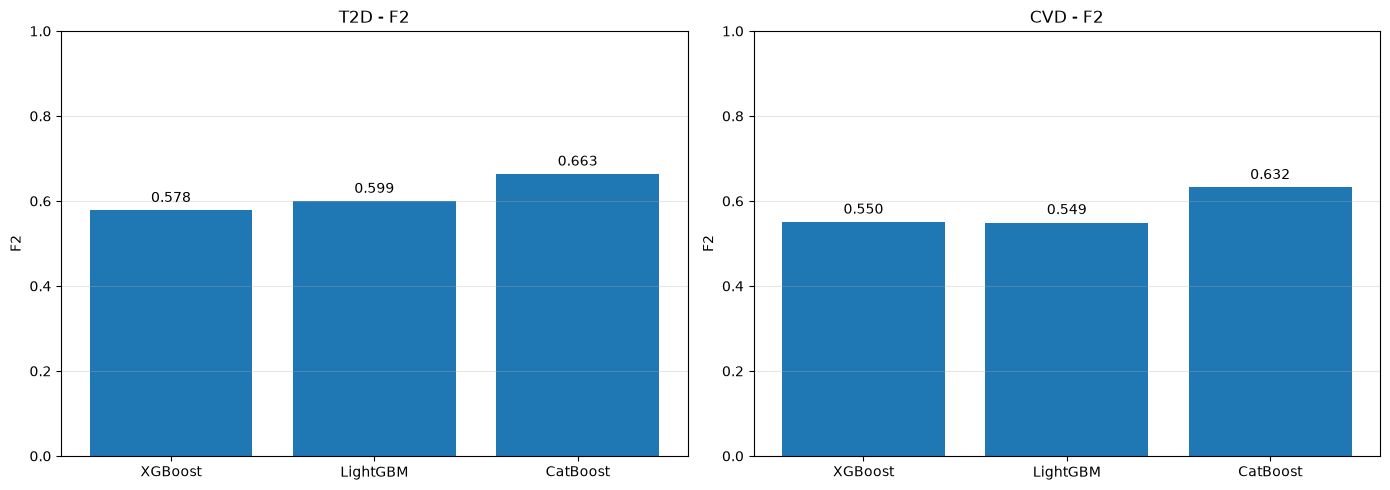

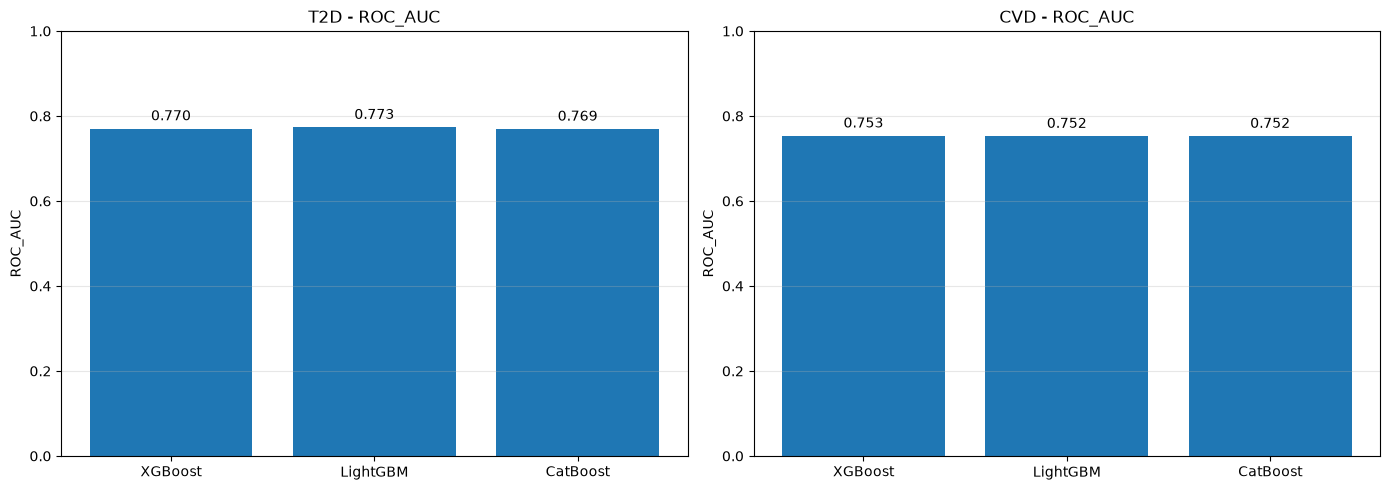

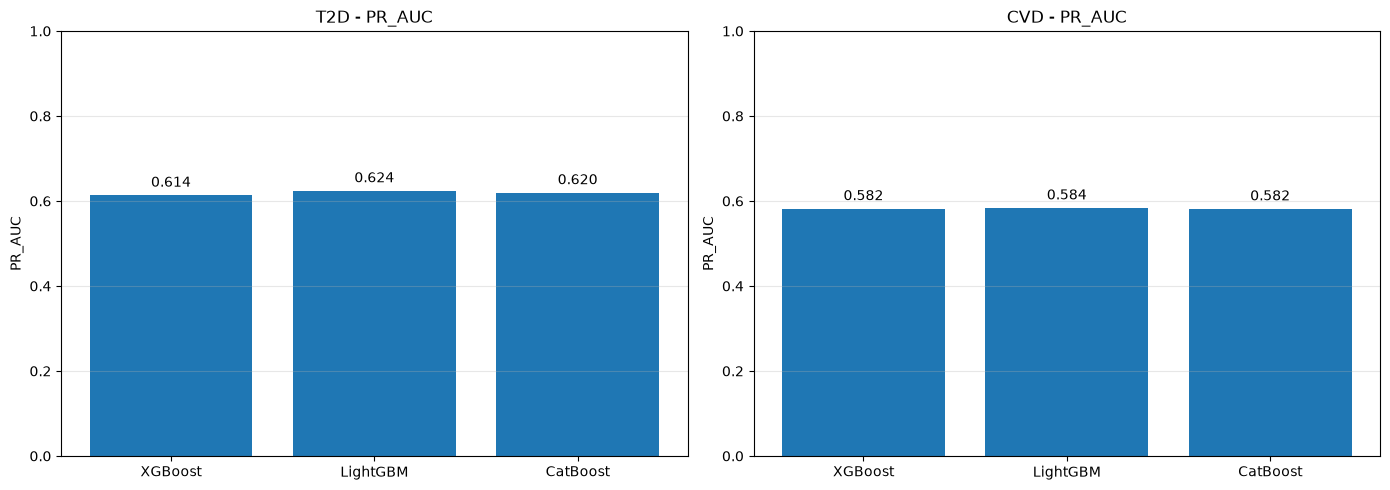

In [19]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "F2",
    "ROC_AUC",
    "PR_AUC"
]
test = results[results["Dataset"] == "Test"]

for metric in metrics:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, disease in zip(axes, ["T2D", "CVD"]):
        data = test[test["Model"].notna()].copy()

        data = results[
            (results["Dataset"] == "Test") &
            (
                results.index.isin(
                    results.index
                )
            )
        ]

        if disease == "T2D":
            data = pd.DataFrame(t2d_results)
        else:
            data = pd.DataFrame(cvd_results)

        data = data[data["Dataset"] == "Test"]

        ax.bar(data["Model"], data[metric])
        ax.set_title(f"{disease} - {metric}")
        ax.set_ylabel(metric)
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.3)

        for i, v in enumerate(data[metric]):
            ax.text(i, v + 0.02, f"{v:.3f}", ha="center")

    plt.tight_layout()
    plt.show()

In [20]:
def plot_confusion(models, X_test, y_test, disease, threshold=0.5):

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, (name, model) in zip(axes, models.items()):
        prob = model.predict_proba(X_test)[:, 1]
        pred = (prob >= threshold).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            pred,
            display_labels=["Không bệnh", "Có bệnh"],
            cmap="Blues",
            ax=ax
        )

        ax.set_title(f"{disease} - {name}")

    plt.tight_layout()
    plt.show()

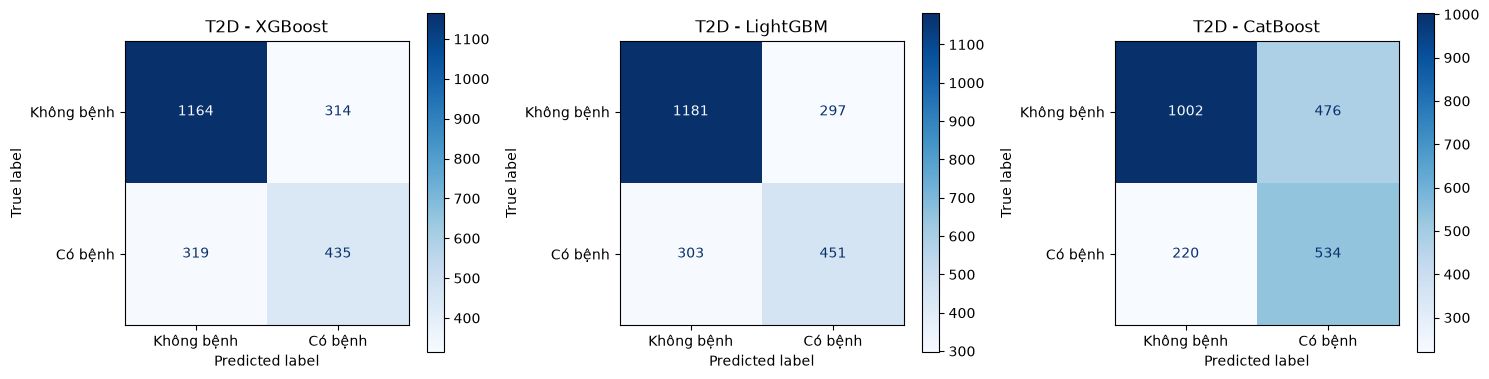

In [21]:
plot_confusion(
    t2d_ft_models,
    X_t2d_test,
    y_t2d_test,
    "T2D"
)

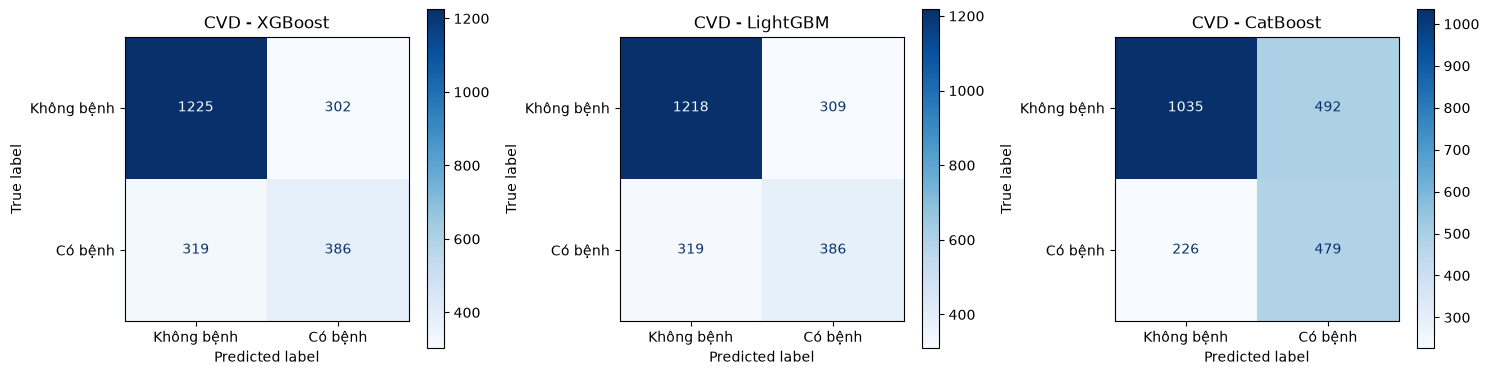

In [22]:
plot_confusion(
    cvd_ft_models,
    X_cvd_test,
    y_cvd_test,
    "CVD"
)

In [23]:
# model = joblib.load(
#     MODEL_DIR / "t2d_ft_xgboost.pkl"
# )

# prob = model.predict_proba(X_t2d_test)[:, 1]
# pred = (prob >= 0.5).astype(int)

### Threshold

In [24]:
def threshold_tuning(models, X_val, y_val, disease):
    rows = []

    for name, model in models.items():
        prob = model.predict_proba(X_val)[:, 1]
        pr_auc = average_precision_score(y_val, prob)

        for threshold in np.arange(0.10, 0.51, 0.05):
            pred = (prob >= threshold).astype(int)

            rows.append({
                "Disease": disease,
                "Model": name,
                "Threshold": round(threshold, 2),
                "Precision": precision_score(
                    y_val, pred, zero_division=0
                ),
                "Recall": recall_score(
                    y_val, pred, zero_division=0
                ),
                "F1": f1_score(
                    y_val, pred, zero_division=0
                ),
                "F2": fbeta_score(
                    y_val, pred, beta=2, zero_division=0
                ),
                "PR_AUC": pr_auc
            })

    return pd.DataFrame(rows)

In [25]:
t2d_threshold = threshold_tuning(
    t2d_ft_models, X_t2d_val, y_t2d_val, "T2D"
)

cvd_threshold = threshold_tuning(
    cvd_ft_models, X_cvd_val, y_cvd_val, "CVD"
)

display(t2d_threshold)
display(cvd_threshold)

,Disease,Model,Threshold,Precision,Recall,F1,F2,PR_AUC
0,T2D,XGBoost,0.10,0.342474,0.989437,0.508828,0.718119,0.597410
1,T2D,XGBoost,0.15,0.375600,0.964789,0.540701,0.734388,0.597410
2,T2D,XGBoost,0.20,0.398169,0.919014,0.555615,0.728440,0.597410
3,T2D,XGBoost,0.25,0.420918,0.871479,0.567661,0.717807,0.597410
4,T2D,XGBoost,0.30,0.451521,0.836268,0.586420,0.714501,0.597410
5,T2D,XGBoost,0.35,0.481442,0.799296,0.600927,0.706065,0.597410
6,T2D,XGBoost,0.40,0.504094,0.758803,0.605762,0.689159,0.597410
7,T2D,XGBoost,0.45,0.524869,0.705986,0.602102,0.660408,0.597410
8,T2D,XGBoost,0.50,0.548239,0.630282,0.586405,0.611966,0.597410
9,T2D,LightGBM,0.10,0.343980,0.985915,0.510018,0.717949,0.598056


,Disease,Model,Threshold,Precision,Recall,F1,F2,PR_AUC
0,CVD,XGBoost,0.10,0.350244,0.987931,0.517148,0.724216,0.623194
1,CVD,XGBoost,0.15,0.378505,0.977586,0.545717,0.742535,0.623194
2,CVD,XGBoost,0.20,0.402493,0.946552,0.564815,0.745114,0.623194
3,CVD,XGBoost,0.25,0.427406,0.903448,0.580288,0.738861,0.623194
4,CVD,XGBoost,0.30,0.461681,0.862069,0.601323,0.734646,0.623194
5,CVD,XGBoost,0.35,0.493644,0.803448,0.611549,0.713848,0.623194
6,CVD,XGBoost,0.40,0.522533,0.739655,0.612420,0.682904,0.623194
7,CVD,XGBoost,0.45,0.549928,0.655172,0.597954,0.631020,0.623194
8,CVD,XGBoost,0.50,0.576389,0.572414,0.574394,0.573204,0.623194
9,CVD,LightGBM,0.10,0.352833,0.987931,0.519964,0.726420,0.622993


In [26]:
import shap
shap.initjs()

def shap_analysis(models, X_test, disease, max_display=20):
    for name, model in models.items():
        print(f"{disease} — {name}")

        explainer   = shap.TreeExplainer(model)
        shap_values = explainer(X_test)

        # Bar plot: feature importance tổng hợp
        fig, ax = plt.subplots(figsize=(10, 6))
        shap.plots.bar(shap_values, max_display=max_display, show=False)
        plt.title(f"{disease} — {name} | Mean |SHAP|", fontsize=13)
        plt.tight_layout()
        plt.show()

        # Beeswarm: phân phối SHAP theo feature
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.plots.beeswarm(shap_values, max_display=max_display, show=False)
        plt.title(f"{disease} — {name} | SHAP Beeswarm", fontsize=13)
        plt.tight_layout()
        plt.show()

T2D — XGBoost


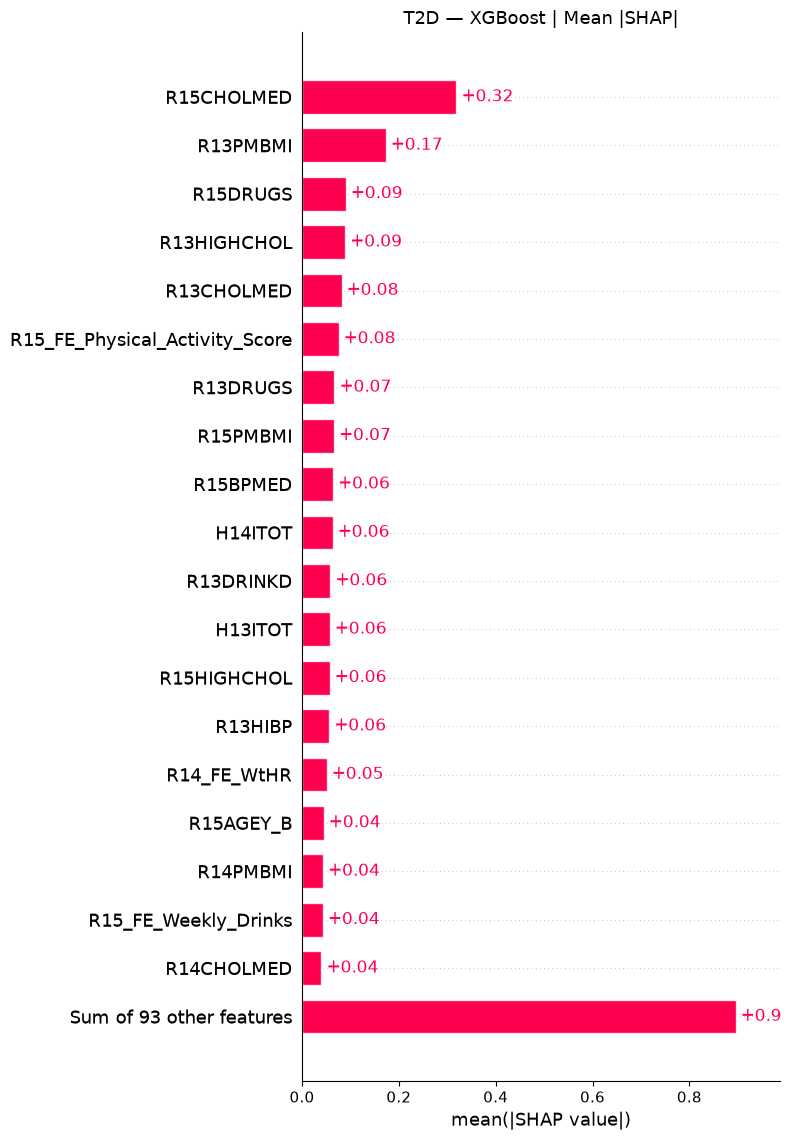

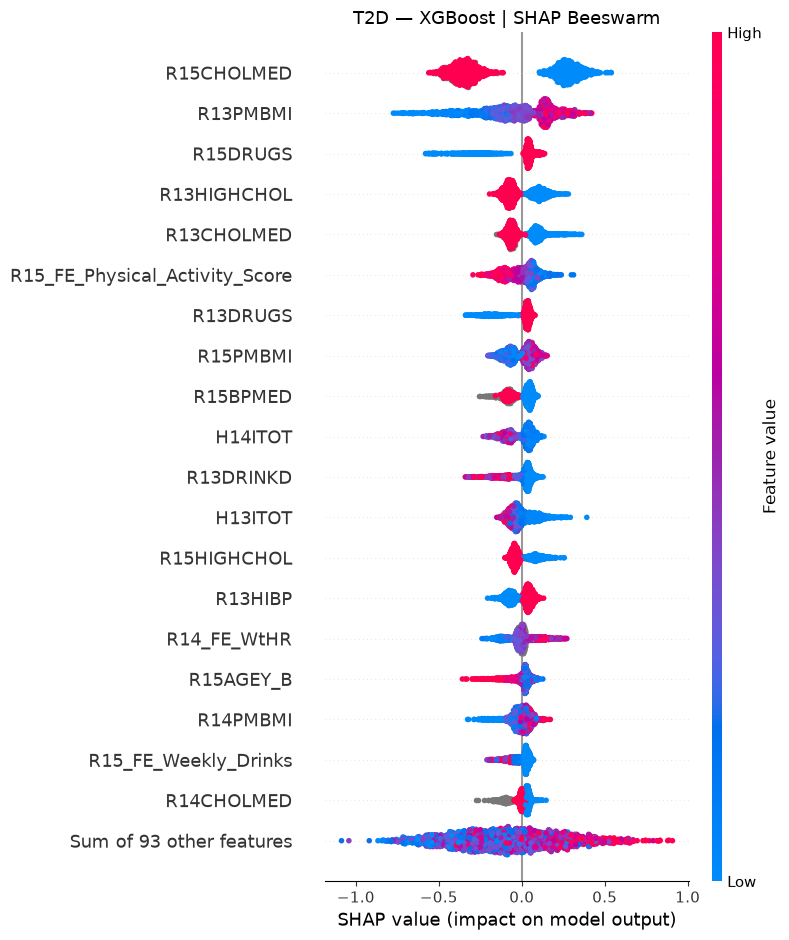

T2D — LightGBM


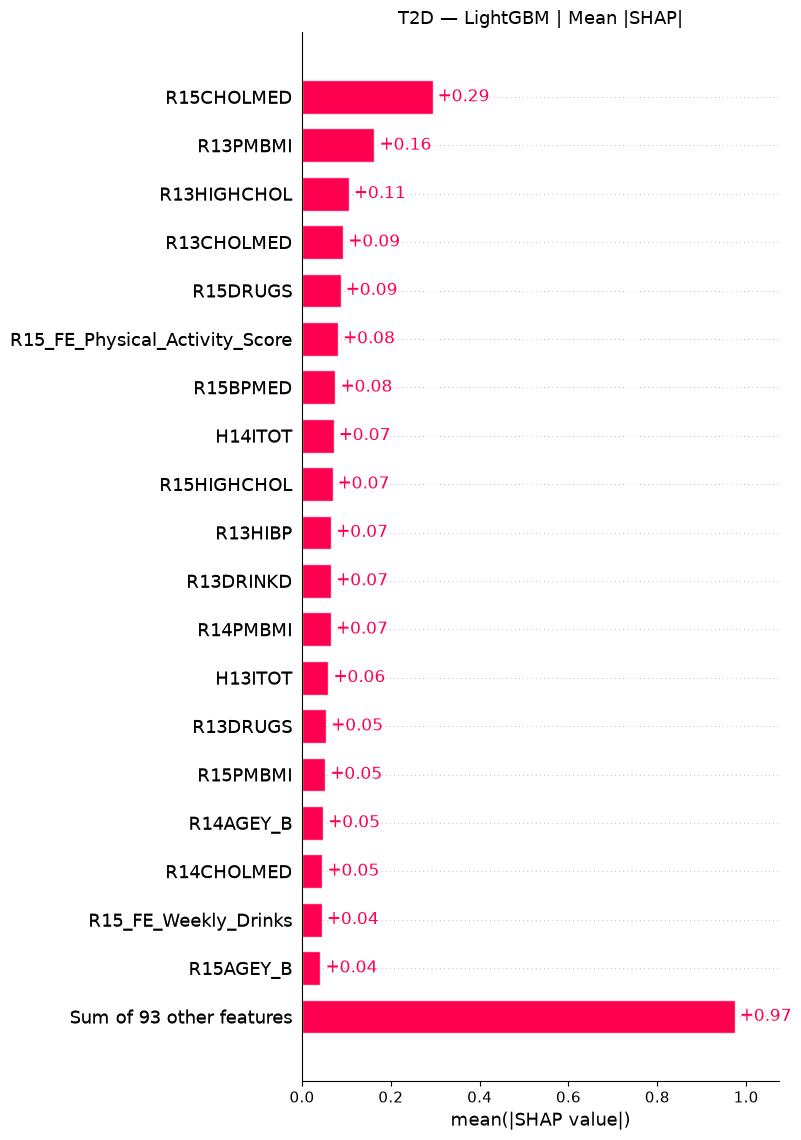

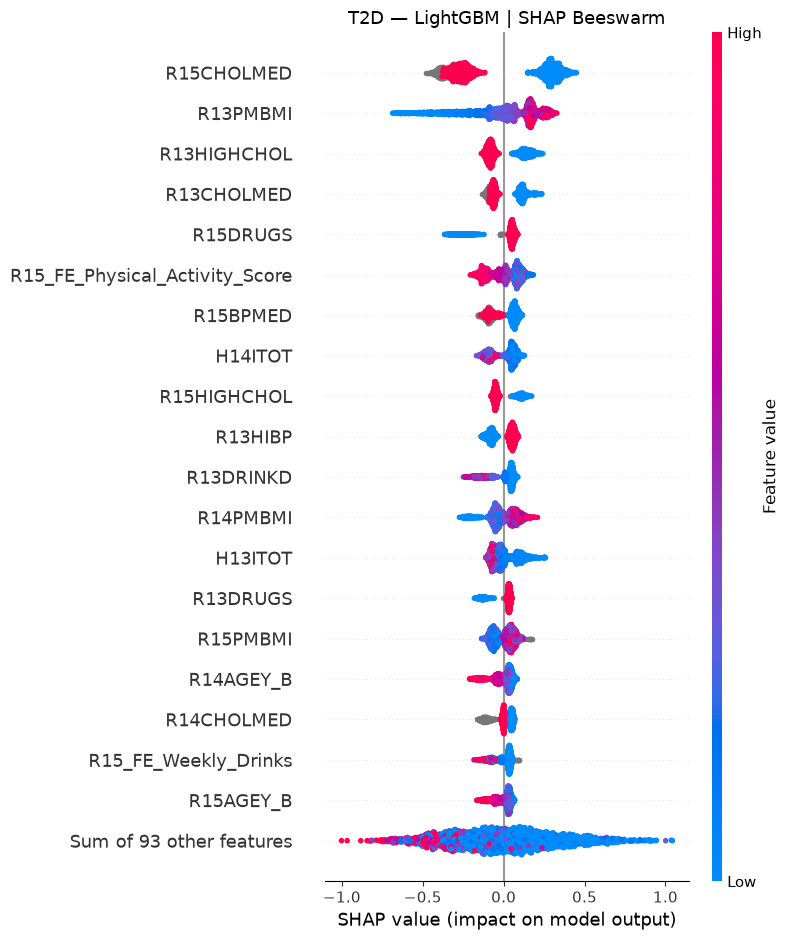

T2D — CatBoost


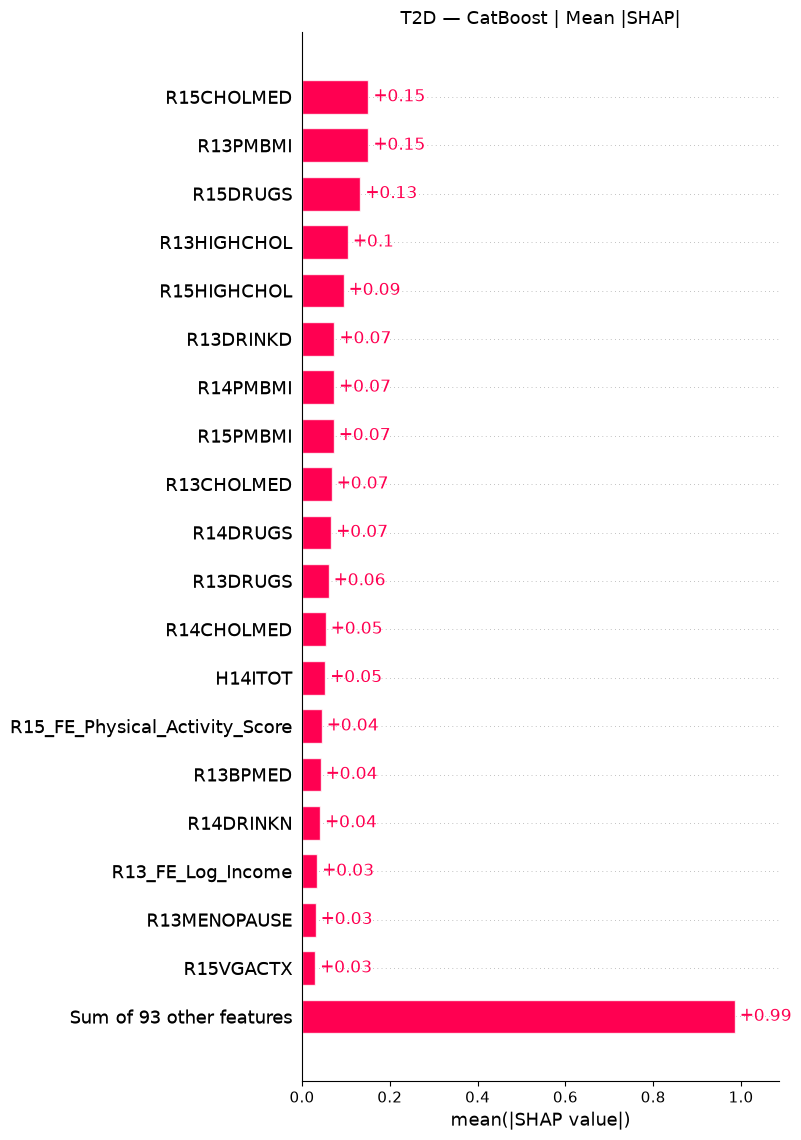

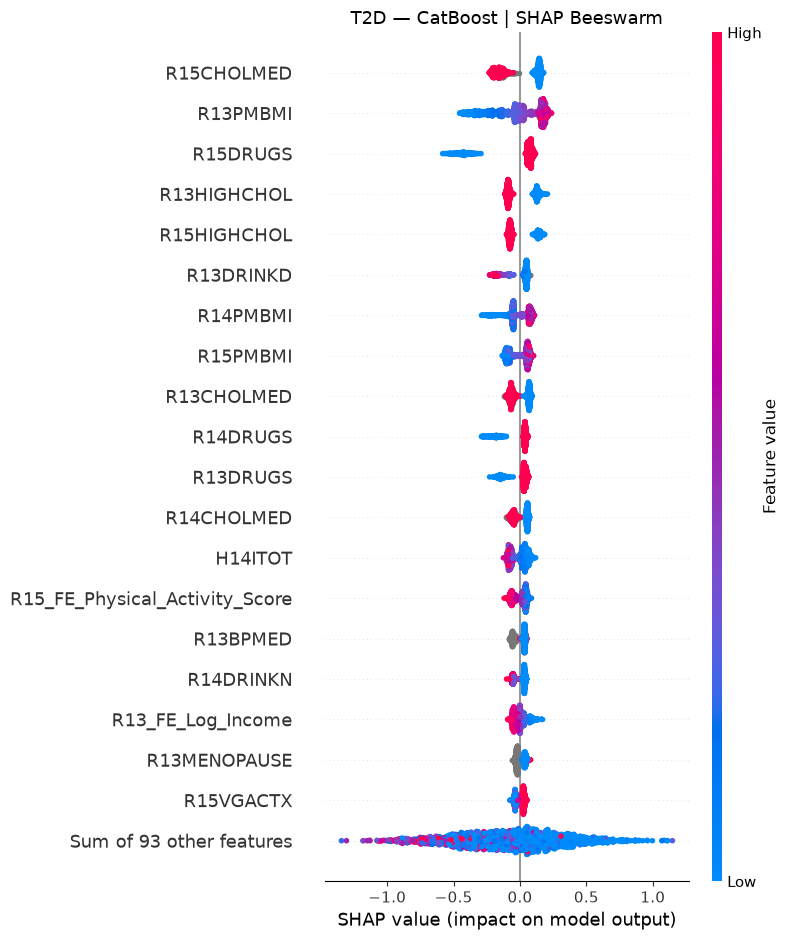

CVD — XGBoost


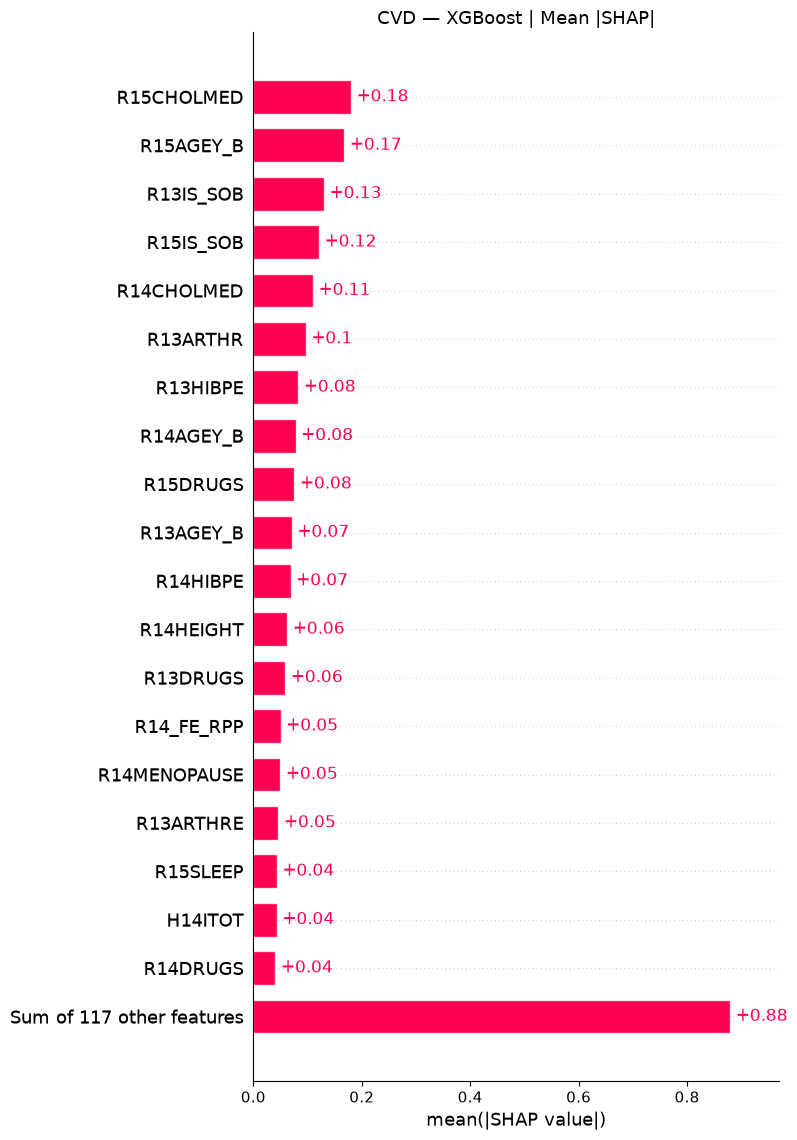

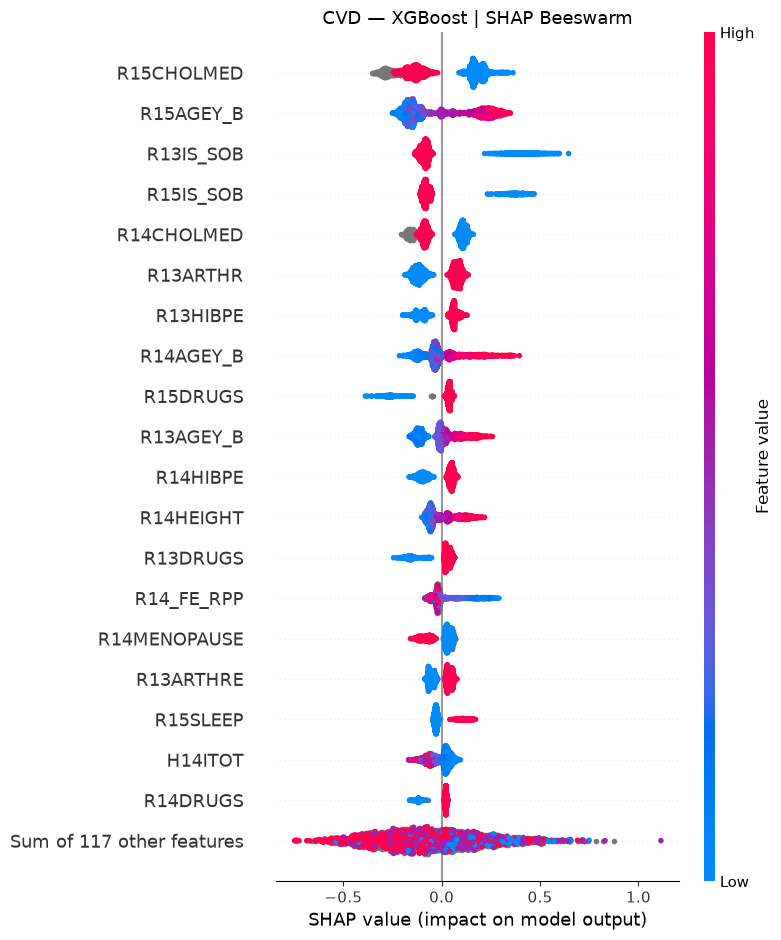

CVD — LightGBM


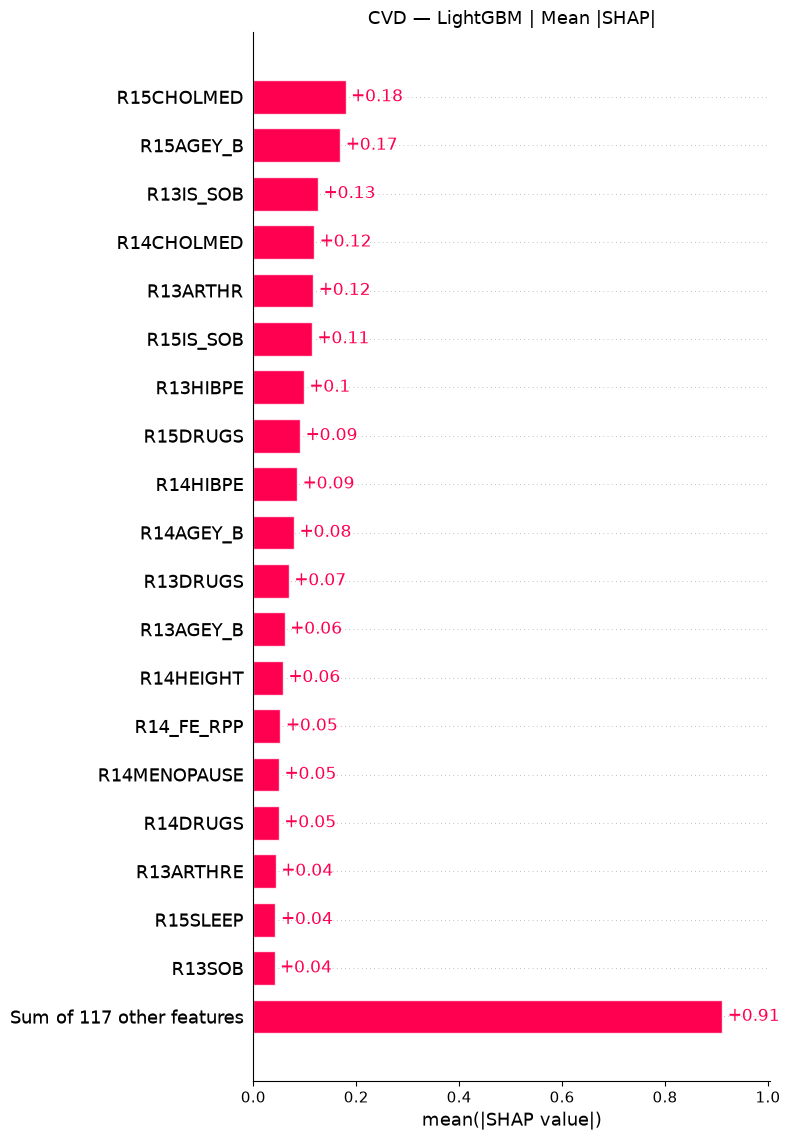

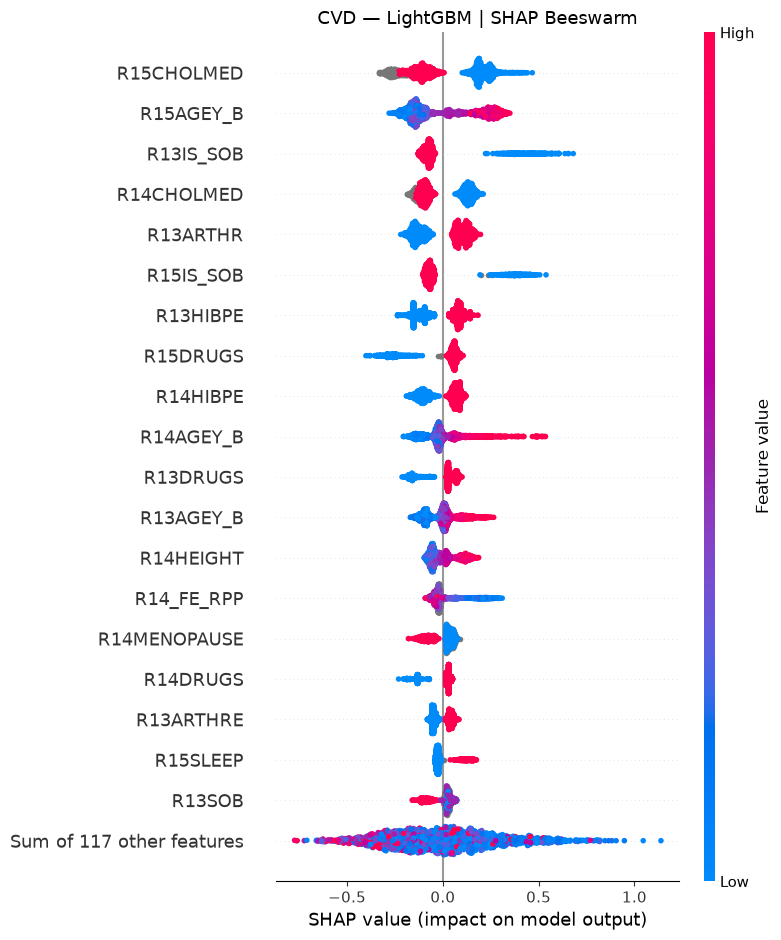

CVD — CatBoost


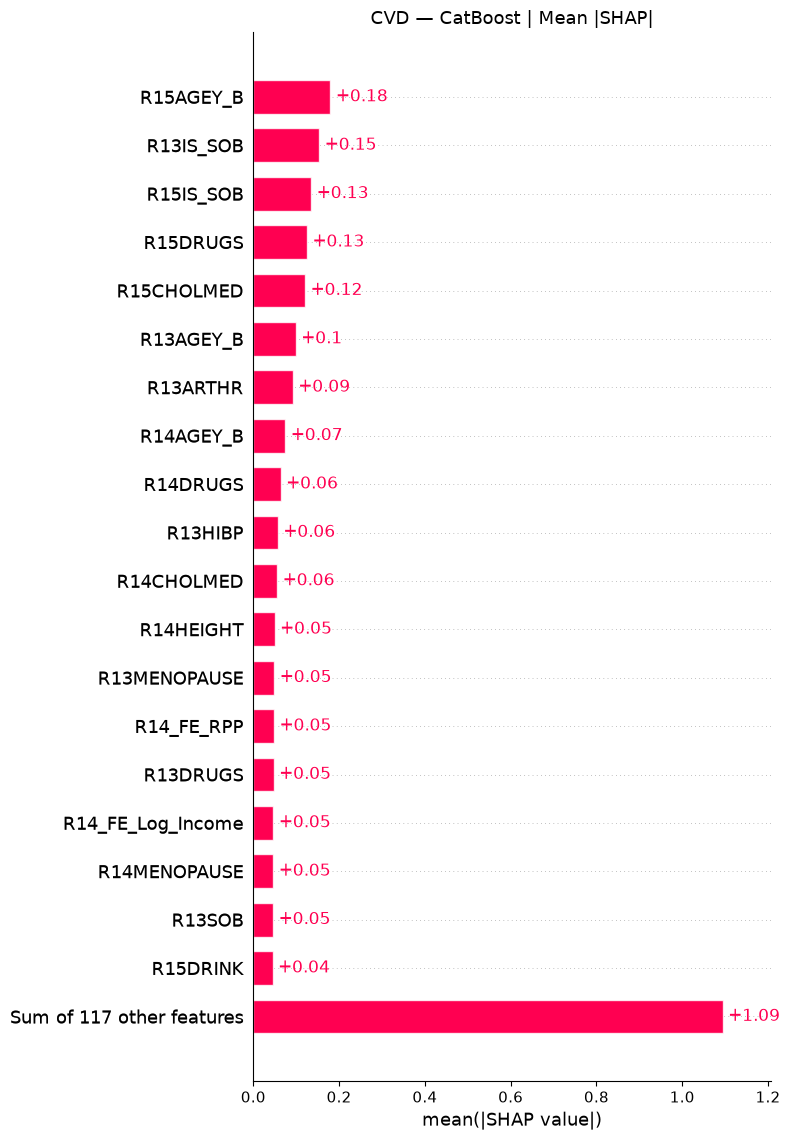

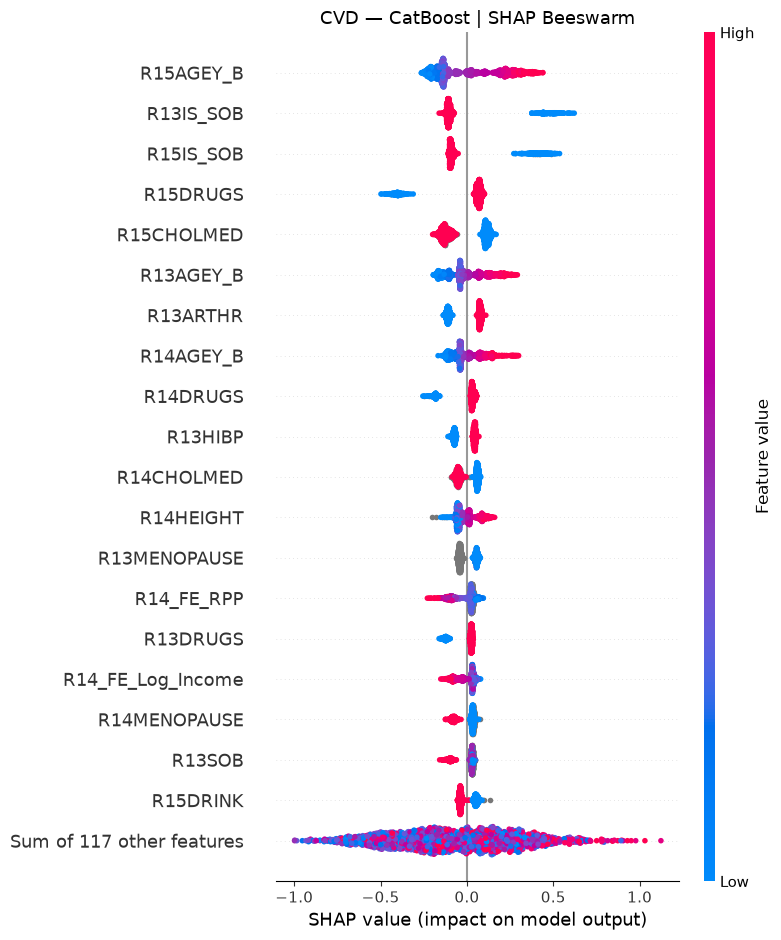

In [27]:
shap_analysis(t2d_ft_models, X_t2d_test, "T2D")
shap_analysis(cvd_ft_models, X_cvd_test, "CVD")

In [28]:
def shap_top_features(models, X_test, disease, top_n=15):
    dfs = []
    for name, model in models.items():
        explainer   = shap.TreeExplainer(model)
        sv          = explainer(X_test)
        importance  = pd.Series(
            np.abs(sv.values).mean(axis=0),
            index=X_test.columns,
            name=name
        )
        dfs.append(importance)

    result = pd.concat(dfs, axis=1).sort_values(
        by=list(models.keys())[0], ascending=False
    ).head(top_n)

    print(f"\n=== Top {top_n} Features — {disease} ===")
    display(result.style.format("{:.4f}").background_gradient(cmap="YlOrRd"))

shap_top_features(t2d_ft_models, X_t2d_test, "T2D")
shap_top_features(cvd_ft_models, X_cvd_test, "CVD")



=== Top 15 Features — T2D ===


,XGBoost,LightGBM,CatBoost
R15CHOLMED,0.3189,0.2939,0.1511
R13PMBMI,0.1727,0.1632,0.1511
R15DRUGS,0.0902,0.0869,0.1327
R13HIGHCHOL,0.0890,0.1053,0.1044
R13CHOLMED,0.0816,0.0927,0.0675
R15_FE_Physical_Activity_Score,0.0754,0.0810,0.0448
R13DRUGS,0.0669,0.0543,0.0605
R15PMBMI,0.0660,0.0524,0.0722
R15BPMED,0.0639,0.0752,0.0281
H14ITOT,0.0631,0.0711,0.0527



=== Top 15 Features — CVD ===


,XGBoost,LightGBM,CatBoost
R15CHOLMED,0.1801,0.1792,0.1206
R15AGEY_B,0.1677,0.1689,0.1796
R13IS_SOB,0.1303,0.1258,0.1535
R15IS_SOB,0.1211,0.1139,0.1349
R14CHOLMED,0.1100,0.1182,0.0556
R13ARTHR,0.0966,0.1165,0.0919
R13HIBPE,0.0827,0.0981,0.0272
R14AGEY_B,0.0779,0.0791,0.0745
R15DRUGS,0.0756,0.0910,0.1250
R13AGEY_B,0.0709,0.0610,0.0988
